Projet Big Data : traitement distribué et modélisation (PySpark)

Ce notebook prend la suite de `webscrapping.ipynb` (collecte). Il lit les fichiers bruts de `data/raw/`, les nettoie avec PySpark, extrait les mots les plus fréquents des descriptions avec une procédure MapReduce, puis entraîne trois modèles PySpark ML pour prédire le salaire annuel d'une offre.

Étape 1 : Architecture et flux de données

```
 ┌────────────────────┐   ┌─────────────────────────┐
 │ API France Travail │   │ Welcome to the Jungle   │
 │ (requests, OAuth2) │   │ (Selenium + BeautifulSoup)│
 └─────────┬──────────┘   └────────────┬────────────┘
           │  INGESTION (webscrapping.ipynb)  │
           ▼                            ▼
 ┌──────────────────────────────────────────────────┐
 │ STOCKAGE BRUT  data/raw/                          │
 │  france_travail_AAAAMMJJ.json (réponse API brute) │
 │  offres_france_travail.csv, offres_wttj.csv       │
 └─────────────────────────┬────────────────────────┘
                           ▼
 ┌──────────────────────────────────────────────────┐
 │ SPARK PROCESSING (ce notebook)                    │
 │  union des sources → doublons → valeurs manquantes│
 │  → salaire annuel → compétences → MapReduce top-k │
 └─────────────────────────┬────────────────────────┘
                           ▼
 ┌──────────────────────────────────────────────────┐
 │ ZONE NETTOYÉE  data/processed/offres_clean.parquet│
 │  (partitionnée par source)                        │
 └─────────────────────────┬────────────────────────┘
                           ▼
 ┌──────────────────────────────────────────────────┐
 │ MODELING (PySpark ML) : régression linéaire,      │
 │ Random Forest, Gradient Boosted Trees → salaire   │
 └──────────────────────────────────────────────────┘
```

Choix des formats.
- *JSON brut* pour la réponse de l'API : c'est le format natif, on le garde sans transformation pour pouvoir rejouer le traitement (principe du data lake « raw zone »).
- *CSV* pour la version aplatie de chaque source : lisible, simple à produire depuis pandas, et lu directement par Spark.
- *Parquet* pour les données nettoyées : format colonnaire et compressé, le schéma est stocké avec les données (pas de ré-inférence des types), et Spark ne lit que les colonnes utiles à chaque requête.

Partitionnement. Les données nettoyées sont partitionnées par `source` (`partitionBy("source")`) : chaque source a un format et une qualité différents, et ce découpage permet de relire ou de recalculer une source sans toucher à l'autre. Avec ~2 000 offres, un partitionnement plus fin (par date ou par département) créerait surtout de très petits fichiers, ce qui dégrade les performances de Spark.

In [1]:
import os, re
from operator import add

import matplotlib.pyplot as plt
import pandas as pd

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer, StopWordsRemover
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

spark = (SparkSession.builder
         .appName("BigData2026-MarcheEmploi")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

RAW_DIR = "data/raw"
PROCESSED_DIR = "data/processed"
SEED = 42

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44673 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44673 -Dhttp.nonProxyHosts=localhost|127.0.0.1

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/23 20:54:18 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/23 20:54:18 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/23 20:54:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1


Étape 4 : Traitement distribué avec Spark

4.1 Chargement des données brutes
Les deux sources ont été aplaties avec le même schéma dans `webscrapping.ipynb`, on les réunit avec `unionByName`. Les descriptions contiennent des retours à la ligne et des guillemets, d'où les options `multiLine` et `escape`.

In [2]:
def lire_csv(nom):
    return (spark.read
            .option("header", True)
            .option("multiLine", True)
            .option("escape", '"')
            .option("encoding", "UTF-8")
            .csv(os.path.join(RAW_DIR, nom)))

df_ft = lire_csv("offres_france_travail.csv")
df_wttj = lire_csv("offres_wttj.csv")
# le BOM utf-8-sig peut se retrouver dans le nom de la première colonne
df_ft = df_ft.toDF(*[c.replace("﻿", "") for c in df_ft.columns])
df_wttj = df_wttj.toDF(*[c.replace("﻿", "") for c in df_wttj.columns])

df_raw = df_ft.unionByName(df_wttj, allowMissingColumns=True)
print(f"France Travail : {df_ft.count()} offres | WTTJ : {df_wttj.count()} offres | total : {df_raw.count()}")
df_raw.groupBy("source").count().show()
df_raw.printSchema()

France Travail : 1045 offres | WTTJ : 1246 offres | total : 2291


+------------------+-----+
|            source|count|
+------------------+-----+
|    France travail| 1045|
|welcometothejungle| 1246|
+------------------+-----+

root
 |-- id: string (nullable = true)
 |-- intitule: string (nullable = true)
 |-- description: string (nullable = true)
 |-- type_contrat: string (nullable = true)
 |-- nb_heure_travail: string (nullable = true)
 |-- experience: string (nullable = true)
 |-- experience_exige: string (nullable = true)
 |-- salaire_libelle: string (nullable = true)
 |-- salaire_min: string (nullable = true)
 |-- salaire_max: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- code_postal: string (nullable = true)
 |-- commune: string (nullable = true)
 |-- entreprise: string (nullable = true)
 |-- secteur_activite: string (nullable = true)
 |-- competences: string (nullable = true)
 |-- formation_requise: string (nullable = true)
 |-- langues: string (nullable = true)
 |-- type_de_poste: string (nullable = true)
 |-- source: st

In [3]:
def taux_manquants(df):
    total = df.count()
    exprs = [(F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ""), 1).otherwise(0)) / total * 100).alias(c)
             for c in df.columns]
    return df.select(exprs).toPandas().T.rename(columns={0: "% manquant"}).round(1)

taux_manquants(df_raw).sort_values("% manquant", ascending=False)

                   % manquant
langues                  97.4
competences              93.4
nb_heure_travail         89.6
formation_requise        81.6
salaire_max              78.2
salaire_min              77.6
salaire_libelle          77.3
experience_exige         30.2
experience               30.2
secteur_activite         27.5
entreprise               14.0
code_postal              12.6
commune                   3.9
description               0.0
intitule                  0.0
id                        0.0
type_contrat              0.0
ville                     0.0
type_de_poste             0.0
source                    0.0

4.2 Nettoyage : doublons et valeurs manquantes

1. Doublons exacts : même `id` dans une source (une offre remontée par plusieurs mots-clés).
2. Doublons inter-sources : une même offre publiée sur France Travail et sur WTTJ a des identifiants différents, on la repère par sa description normalisée (minuscules, sans ponctuation ni espaces).
3. Valeurs manquantes : les colonnes catégorielles reçoivent la modalité « Non renseigné » (l'absence d'information est elle-même informative) ; l'expérience numérique manquante sera imputée par la médiane dans le pipeline ML ; les offres sans description ni intitulé sont supprimées.

In [4]:
n0 = df_raw.count()
df = df_raw.dropDuplicates(["source", "id"])
n1 = df.count()

df = (df
      .withColumn("desc_norm", F.regexp_replace(F.lower(F.coalesce("description", F.lit(""))), r"[^a-z0-9àâçéèêëîïôûùüÿœ]", ""))
      .withColumn("desc_norm", F.when(F.length("desc_norm") > 50, F.col("desc_norm"))))
# on ne déduplique que les offres ayant une vraie description, en gardant la version France Travail (plus complète)
avec_desc = df.filter(F.col("desc_norm").isNotNull())
sans_desc = df.filter(F.col("desc_norm").isNull())
from pyspark.sql.window import Window
w = Window.partitionBy("desc_norm").orderBy(F.col("source").asc())
avec_desc = avec_desc.withColumn("_rang", F.row_number().over(w)).filter("_rang = 1").drop("_rang")
df = avec_desc.unionByName(sans_desc).drop("desc_norm")
n2 = df.count()

df = df.filter(F.col("intitule").isNotNull() & F.col("description").isNotNull())
n3 = df.count()
print(f"Brut : {n0} | après doublons id : {n1} | après doublons inter-sources : {n2} | après suppression des offres vides : {n3}")

Brut : 2291 | après doublons id : 2291 | après doublons inter-sources : 2232 | après suppression des offres vides : 2232


4.3 Normalisation du salaire (variable cible)

Les libellés n'ont pas le même format selon la source :
- France Travail : « Annuel de 40000.0 Euros à 47000.0 Euros sur 12 mois », « Mensuel de 1407.0 Euros à 1638.0 Euros », « Horaire de 11.88 Euros » ;
- WTTJ : le scraper reprend le même format (« Annuel de 48000 Euros à 76000 Euros », « Mensuel de 935 Euros à 1682 Euros »), avec en plus des taux journaliers pour les missions freelance (« Journalier de 300 Euros »).

On extrait les montants, on prend le milieu de la fourchette et on ramène tout à un salaire annuel brut : ×12 pour un mensuel, ×1 607 h (durée légale annuelle) pour un horaire, un montant inférieur à 5 000 € annoncé « / an » est considéré comme mensuel et, à l'inverse, un « mensuel » supérieur à 10 000 € est en réalité annuel. Les valeurs hors de [6 000 ; 200 000] € sont jugées aberrantes et mises à null. Les taux journaliers des freelances (TJM) sont aussi écartés : ils correspondent à un chiffre d'affaires, qui doit couvrir charges et périodes sans mission, et ne sont pas comparables à un salaire brut.

In [5]:
@F.udf(T.DoubleType())
def salaire_annuel(libelle):
    if libelle is None:
        return None
    lib = libelle.lower().replace("\xa0", " ")
    lib = re.sub(r"sur\s+[\d.,]+\s+mois", "", lib)
    montants = []
    for nombre, k in re.findall(r"(\d+(?:[.,]\d+)?)\s*(k?)", lib):
        valeur = float(nombre.replace(",", "."))
        montants.append(valeur * 1000 if k else valeur)
    montants = [m for m in montants if m > 0]
    if not montants:
        return None
    moyenne = sum(montants[:2]) / len(montants[:2])
    if "horaire" in lib or "heure" in lib:
        annuel = moyenne * 1607
    elif "journalier" in lib or re.search(r"(par|/) ?jour\b", lib):
        return None             # taux journalier de freelance (TJM) : un chiffre d'affaires, pas un salaire
    elif ("mensuel" in lib or "mois" in lib) and moyenne > 10000:
        annuel = moyenne        # montant annuel saisi par erreur comme mensuel (ex. « Mensuel de 26000 Euros »)
    elif "mensuel" in lib or "mois" in lib or moyenne < 5000:
        annuel = moyenne * 12
    else:
        annuel = moyenne
    return float(annuel) if 6000 <= annuel <= 200000 else None

df = df.withColumn("salaire_annuel", salaire_annuel("salaire_libelle"))
df.select("source", "salaire_libelle", "salaire_annuel").filter(F.col("salaire_libelle").isNotNull()).show(10, truncate=60)
df.groupBy("source").agg(F.count("*").alias("offres"),
                         F.count("salaire_annuel").alias("avec_salaire"),
                         F.round(F.expr("percentile_approx(salaire_annuel, 0.5)"), 0).alias("salaire_median")).show()

+------------------+---------------------------------------+--------------+
|            source|                        salaire_libelle|salaire_annuel|
+------------------+---------------------------------------+--------------+
|welcometothejungle|    Annuel de 55000 Euros à 74000 Euros|       64500.0|
|    France travail|Annuel de 50000.0 Euros à 55000.0 Euros|       52500.0|
|    France travail|Annuel de 45000.0 Euros à 50000.0 Euros|       47500.0|
|welcometothejungle|                  Annuel de 70000 Euros|       70000.0|
|welcometothejungle|    Annuel de 39000 Euros à 45000 Euros|       42000.0|
|welcometothejungle|    Annuel de 40000 Euros à 42000 Euros|       41000.0|
|welcometothejungle|      Mensuel de 935 Euros à 1682 Euros|       15702.0|
|    France travail|Annuel de 38000.0 Euros à 42000.0 Euros|       40000.0|
|welcometothejungle|     Mensuel de 1000 Euros à 1200 Euros|       13200.0|
|welcometothejungle|    Annuel de 45000 Euros à 55000 Euros|       50000.0|
+-----------

+------------------+------+------------+--------------+
|            source|offres|avec_salaire|salaire_median|
+------------------+------+------------+--------------+
|    France travail|  1016|         278|       47500.0|
|welcometothejungle|  1216|         210|       45000.0|
+------------------+------+------------+--------------+



4.4 Variables explicatives

- `categorie_poste` : déduite de l'intitulé (Data Engineer, Data Scientist, Data Analyst, ML / IA, BI…), plus fiable que le mot-clé de recherche.
- `niveau_poste` : séniorité lue dans l'intitulé (Junior, Senior / Confirmé, Lead / Manager).
- `contrat`, `niveau_formation` (harmonisé : Bac+2, Bac+3, Bac+5 et plus), `region` (Île-de-France / autres régions / étranger, depuis le code postal).
- `annees_experience` : depuis le champ expérience de France Travail (« 3 An(s) », « 6 Mois », « Débutant accepté ») ou, à défaut, depuis la description (« 3 ans d'expérience »).
- `skill_*` : présence de 22 compétences techniques dans la description et les compétences listées.

In [6]:
texte = F.lower(F.concat_ws(" ", "intitule", "description", "competences"))
titre = F.lower(F.col("intitule"))

df = df.withColumn("categorie_poste",
    F.when(titre.rlike(r"stagi|stage|alternan|apprenti"), "Stage / Alternance")
     .when(titre.rlike(r"machine learning|ml |mlops|\bia\b|\bai\b|intelligence artificielle|deep learning"), "ML / IA")
     .when(titre.rlike(r"scien"), "Data Scientist")
     .when(titre.rlike(r"engineer|ingénieur|ingenieur|architect|devops|développeur|developpeur"), "Data Engineer")
     .when(titre.rlike(r"\bbi\b|business intelligence|power bi|décisionnel|decisionnel"), "BI")
     .when(titre.rlike(r"analy"), "Data Analyst")
     .when(titre.rlike(r"manager|chef|lead|head|directeur|responsable"), "Management")
     .otherwise("Autre"))

df = df.withColumn("contrat",
    F.when(F.col("type_contrat").rlike(r"(?i)cdi"), "CDI")
     .when(F.col("type_contrat").rlike(r"(?i)cdd|temporaire|intérim|mission"), "CDD / Intérim")
     .when(F.col("type_contrat").rlike(r"(?i)stage|alternance|apprentissage"), "Stage / Alternance")
     .when(F.col("type_contrat").rlike(r"(?i)freelance|indépendant|libéral"), "Freelance")
     .when(F.col("type_contrat").isNull(), "Non renseigné")
     .otherwise("Autre"))

formation = F.lower(F.coalesce("formation_requise", F.lit("")))
df = df.withColumn("niveau_formation",
    F.when(formation.rlike(r"bac\+5|master|postgraduate|doctor|ingénieur"), "Bac+5 et plus")
     .when(formation.rlike(r"bac\+3|bac\+4|licence|bachelor"), "Bac+3/4")
     .when(formation.rlike(r"bac\+2|bts|dut|associate|bac ou|cap|bep|sans diplôme"), "Bac+2 et moins")
     .otherwise("Non renseigné"))

cp = F.lpad(F.regexp_extract(F.coalesce("code_postal", F.lit("")), r"^(\d+)", 1), 5, "0")
dep = F.substring(cp, 1, 2)
df = df.withColumn("region",
    F.when(F.col("code_postal").isNull(), "Non renseigné")
     .when(dep.isin("75", "77", "78", "91", "92", "93", "94", "95") & (F.length(F.regexp_extract("code_postal", r"^(\d+)", 1)) >= 4), "Île-de-France")
     .when(F.col("source") == "welcometothejungle",
           F.when(F.col("commune").rlike(r"(?i)barcelona|london|berlin|madrid|lisboa|bruxelles|genève|luxembourg|amsterdam|milano|new york"), "Étranger")
            .otherwise("Autres régions"))
     .otherwise("Autres régions"))

df = df.withColumn("niveau_poste",
    F.when(titre.rlike(r"senior|sénior|confirm|expérimenté|experimente|expert|\bsr\b"), "Senior / Confirmé")
     .when(titre.rlike(r"lead|principal|head|manager|directeur|directrice|chef|responsable"), "Lead / Manager")
     .when(titre.rlike(r"junior|débutant|debutant|\bjr\b|graduate"), "Junior")
     .otherwise("Non précisé"))

exp_txt = F.lower(F.coalesce("experience", F.lit("")))
nb_ans = F.regexp_extract(exp_txt, r"(\d+)\s*an", 1)
nb_mois = F.regexp_extract(exp_txt, r"(\d+)\s*mois", 1)
desc_ans = F.regexp_extract(F.lower("description"), r"(\d{1,2})\s*(?:\+\s*)?(?:ans|années|years)\s+(?:d.|of\s+)?(?:expérience|experience)", 1)
df = df.withColumn("annees_experience",
    F.when(nb_ans != "", nb_ans.cast("double"))
     .when(nb_mois != "", F.round(nb_mois.cast("double") / 12, 1))
     .when(exp_txt.rlike(r"débutant"), F.lit(0.0))
     .when(desc_ans != "", desc_ans.cast("double"))
     .otherwise(F.lit(None).cast("double")))
df = df.withColumn("annees_experience", F.when(F.col("annees_experience") <= 20, F.col("annees_experience")))

SKILLS = {
    "python": r"\bpython\b", "sql": r"\bsql\b|mysql|postgres", "r": r"\blangage r\b|\br\b,|\br/|, r\b|\brstudio\b",
    "spark": r"\bspark\b|pyspark", "hadoop": r"hadoop|hdfs|hive", "aws": r"\baws\b|amazon web services",
    "azure": r"azure", "gcp": r"\bgcp\b|google cloud|bigquery", "power_bi": r"power ?bi", "tableau": r"\btableau\b",
    "excel": r"\bexcel\b|vba", "machine_learning": r"machine learning|apprentissage automatique",
    "deep_learning": r"deep learning|tensorflow|pytorch|keras", "nlp_llm": r"\bnlp\b|\bllm|genai|ia générative|generative ai",
    "docker_k8s": r"docker|kubernetes", "airflow": r"airflow", "dbt": r"\bdbt\b", "snowflake": r"snowflake",
    "databricks": r"databricks", "sas": r"\bsas\b", "git": r"\bgit\b|github|gitlab", "statistiques": r"statisti",
}
for nom, motif in SKILLS.items():
    df = df.withColumn(f"skill_{nom}", texte.rlike(motif).cast("int"))
SKILL_COLS = [f"skill_{s}" for s in SKILLS]
df = df.withColumn("nb_skills", sum(F.col(c) for c in SKILL_COLS))

df.select("intitule", "categorie_poste", "niveau_poste", "contrat", "niveau_formation", "region", "annees_experience", "nb_skills", "salaire_annuel").show(10, truncate=40)

+----------------------------------------+---------------+-----------------+------------------+----------------+--------------+-----------------+---------+--------------+
|                                intitule|categorie_poste|     niveau_poste|           contrat|niveau_formation|        region|annees_experience|nb_skills|salaire_annuel|
+----------------------------------------+---------------+-----------------+------------------+----------------+--------------+-----------------+---------+--------------+
|                 IA Manager - Lyon (H/F)|        ML / IA|   Lead / Manager|               CDI|   Non renseigné|Autres régions|              5.0|        1|          NULL|
|               Ingénieur IA Vision (H/F)|        ML / IA|      Non précisé|     CDD / Intérim|   Non renseigné|Autres régions|              0.0|        3|          NULL|
|                    Senior Data Engineer|  Data Engineer|Senior / Confirmé|               CDI|   Non renseigné| Non renseigné|             NULL|

Filtrage du périmètre. Les recherches par mots-clés de France Travail remontent aussi des offres hors sujet (agent de conditionnement, électricien…). On garde les offres dont l'intitulé relève de la data, ou dont la description cite au moins 3 des compétences techniques ci-dessus.

In [7]:
MOTIF_DATA = (r"data|donn[ée]e|analy|\bbi\b|business intelligence|machine learning|\bia\b|\bai\b|intelligence artificielle"
              r"|statisti|scien|quant|décisionnel|decisionnel|dataviz|mlops|llm|nlp")
avant = df.groupBy("source").count().withColumnRenamed("count", "avant")
df = df.filter(F.lower("intitule").rlike(MOTIF_DATA) | (F.col("nb_skills") >= 3))
avant.join(df.groupBy("source").count().withColumnRenamed("count", "après"), "source").show()

+------------------+-----+-----+
|            source|avant|après|
+------------------+-----+-----+
|    France travail| 1016|  926|
|welcometothejungle| 1216| 1178|
+------------------+-----+-----+



In [8]:
# valeurs manquantes après nettoyage, sur les variables utilisées par la suite
COLS_ANALYSE = ["categorie_poste", "niveau_poste", "contrat", "niveau_formation", "region", "annees_experience", "nb_skills", "salaire_annuel"]
taux_manquants(df.select(COLS_ANALYSE))

                   % manquant
categorie_poste           0.0
niveau_poste              0.0
contrat                   0.0
niveau_formation          0.0
region                    0.0
annees_experience        29.2
nb_skills                 0.0
salaire_annuel           78.6

4.5 Sauvegarde au format Parquet, partitionné par source

In [9]:
df = df.cache()
(df.drop("competences", "langues")
   .write.mode("overwrite")
   .partitionBy("source")
   .parquet(os.path.join(PROCESSED_DIR, "offres_clean.parquet")))

df_clean = spark.read.parquet(os.path.join(PROCESSED_DIR, "offres_clean.parquet"))
print(f"{df_clean.count()} offres nettoyées relues depuis Parquet")
print(sorted(os.listdir(os.path.join(PROCESSED_DIR, "offres_clean.parquet"))))

2104 offres nettoyées relues depuis Parquet
['._SUCCESS.crc', '_SUCCESS', 'source=France travail', 'source=welcometothejungle']


4.6 Analyse NLP : top-k mots des descriptions (MapReduce)

Implémentation explicite du schéma MapReduce avec l'API RDD de Spark :
- Map (`flatMap`) : chaque description est découpée en mots (minuscules, sans ponctuation), puis chaque mot utile est émis sous la forme d'une paire `(mot, 1)` ;
- Shuffle : Spark regroupe les paires de même clé sur la même partition ;
- Reduce (`reduceByKey`) : les compteurs de chaque mot sont additionnés ;
- Top-k : `takeOrdered(k)` récupère les k mots les plus fréquents sans trier tout le RDD.

Les mots vides français et anglais (listes fournies par `StopWordsRemover` de Spark ML) et le vocabulaire générique des annonces sont filtrés.

In [10]:
K = 30
STOPWORDS = set(StopWordsRemover.loadDefaultStopWords("french")) | set(StopWordsRemover.loadDefaultStopWords("english"))
STOPWORDS |= {"h/f", "f/h", "hf", "fh", "h", "f", "être", "plus", "afin", "ainsi", "tant", "sein", "chez", "dont", "tous",
              "toutes", "tout", "toute", "nos", "notre", "vos", "votre", "leurs", "leur", "aussi", "très", "bien", "faire",
              "etc", "via", "car", "comme", "entre", "selon", "lors", "sous", "sans", "avoir", "peut", "êtes", "serez",
              "poste", "mission", "missions", "profil", "recherché", "descriptif", "vous", "nous", "ans", "an", "mois", "jours",
              "will", "within", "also", "new", "work", "voir", "mise", "place"}

def tokeniser(texte):
    mots = re.findall(r"[a-zàâçéèêëîïôûùüÿœ][a-zàâçéèêëîïôûùüÿœ+#.\-]*[a-zàâçéèêëîïôûùüÿœ+#]|[a-z]", (texte or "").lower())
    return [m for m in mots if len(m) > 2 and m not in STOPWORDS]

rdd_desc = df_clean.select("description").rdd.map(lambda row: row["description"])

paires = rdd_desc.flatMap(tokeniser).map(lambda mot: (mot, 1))     # MAP
comptes = paires.reduceByKey(add)                                  # SHUFFLE + REDUCE
top_k = comptes.takeOrdered(K, key=lambda kv: -kv[1])              # TOP-K

print(f"{paires.count()} mots émis, {comptes.count()} mots distincts")
pd.DataFrame(top_k, columns=["mot", "occurrences"])

574254 mots émis, 24487 mots distincts


              mot  occurrences
0            data        10637
1         données         7682
2      expérience         3128
3          équipe         2982
4       solutions         2715
5         équipes         2706
6   développement         2617
7          outils         2389
8   environnement         2338
9         analyse         2176
10        projets         2152
11    compétences         2113
12        clients         2075
13     techniques         2027
14        qualité         1976
15        métiers         1898
16        modèles         1888
17      technique         1628
18        gestion         1596
19     entreprise         1591
20         groupe         1476
21          cloud         1468
22         python         1467
23       maîtrise         1413
24       capacité         1397
25    performance         1395
26     développer         1394
27        travail         1339
28     production         1318
29       learning         1309

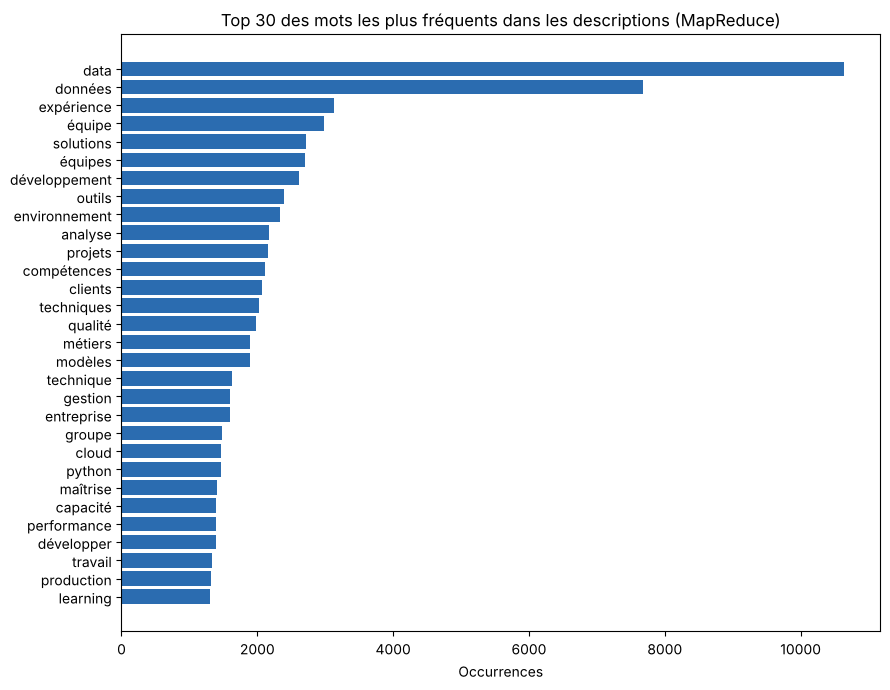

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
mots, n = zip(*top_k[::-1])
ax.barh(mots, n, color="#2b6cb0")
ax.set_title(f"Top {K} des mots les plus fréquents dans les descriptions (MapReduce)")
ax.set_xlabel("Occurrences")
plt.tight_layout()
plt.show()

Même procédure MapReduce, mais avec une clé composite `(source, mot)` pour comparer le vocabulaire des deux sources :

In [12]:
top_par_source = (df_clean.select("source", "description").rdd
                  .flatMap(lambda r: [((r["source"], m), 1) for m in tokeniser(r["description"])])
                  .reduceByKey(add)
                  .map(lambda kv: (kv[0][0], (kv[0][1], kv[1])))
                  .groupByKey()
                  .mapValues(lambda v: sorted(v, key=lambda x: -x[1])[:15])
                  .collect())
pd.DataFrame({src: [f"{m} ({c})" for m, c in mots] for src, mots in top_par_source})

      welcometothejungle        France travail
0            data (5452)           data (5185)
1         données (3709)        données (3973)
2          équipe (1922)     expérience (1555)
3   développement (1600)        équipes (1213)
4      expérience (1573)      solutions (1143)
5       solutions (1572)         équipe (1060)
6         équipes (1493)        qualité (1035)
7          outils (1447)  développement (1017)
8         analyse (1401)        métiers (1011)
9   environnement (1333)  environnement (1005)
10    compétences (1285)         projets (974)
11        clients (1208)          outils (942)
12        projets (1178)      techniques (922)
13        modèles (1149)         clients (867)
14     techniques (1105)     compétences (828)

4.7 Analyse des compétences et des salaires

In [13]:
total = df_clean.count()
freq_skills = (df_clean.select([F.sum(c).alias(c.replace("skill_", "")) for c in SKILL_COLS])
               .toPandas().T.rename(columns={0: "offres"}).sort_values("offres", ascending=False))
freq_skills["% des offres"] = (freq_skills["offres"] / total * 100).round(1)

# salaire médian des offres qui demandent / ne demandent pas chaque compétence
avec_sal = df_clean.filter(F.col("salaire_annuel").isNotNull())
ecarts = []
for c in SKILL_COLS:
    r = avec_sal.groupBy(c).agg(F.expr("percentile_approx(salaire_annuel, 0.5)").alias("med")).collect()
    med = {row[c]: row["med"] for row in r}
    ecarts.append((c.replace("skill_", ""), med.get(1), med.get(0)))
ecarts = pd.DataFrame(ecarts, columns=["compétence", "médiane avec", "médiane sans"]).set_index("compétence")
freq_skills.join(ecarts)

                  offres  % des offres  médiane avec  médiane sans
python              1063          50.5       50000.0       45000.0
sql                  871          41.4       50000.0       45000.0
r                    580          27.6       47500.0       48425.0
nlp_llm              540          25.7       52500.0       46000.0
machine_learning     508          24.1       50000.0       47500.0
power_bi             429          20.4       44500.0       50000.0
statistiques         392          18.6       42500.0       50000.0
git                  385          18.3       50000.0       47500.0
gcp                  367          17.4       53000.0       45000.0
azure                331          15.7       52500.0       46000.0
aws                  302          14.4       52500.0       47000.0
excel                282          13.4       37500.0       50000.0
spark                263          12.5       52500.0       47500.0
deep_learning        255          12.1       48425.0       475

+------------------+------+--------------+-------------+
|   categorie_poste|offres|salaire_median|salaire_moyen|
+------------------+------+--------------+-------------+
|           ML / IA|    84|       55000.0|      56930.0|
|     Data Engineer|   114|       52500.0|      54741.0|
|        Management|    46|       49500.0|      50714.0|
|    Data Scientist|    30|       48425.0|      49838.0|
|                BI|    13|       47500.0|      48847.0|
|             Autre|    34|       44196.0|      42378.0|
|      Data Analyst|    78|       42500.0|      43357.0|
|Stage / Alternance|    52|       15600.0|      16122.0|
+------------------+------+--------------+-------------+



/tmp/ipykernel_1458/2170248359.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot([pdf_sal.loc[pdf_sal.categorie_poste == c, "salaire_annuel"] for c in ordre], tick_labels=ordre, vert=False)


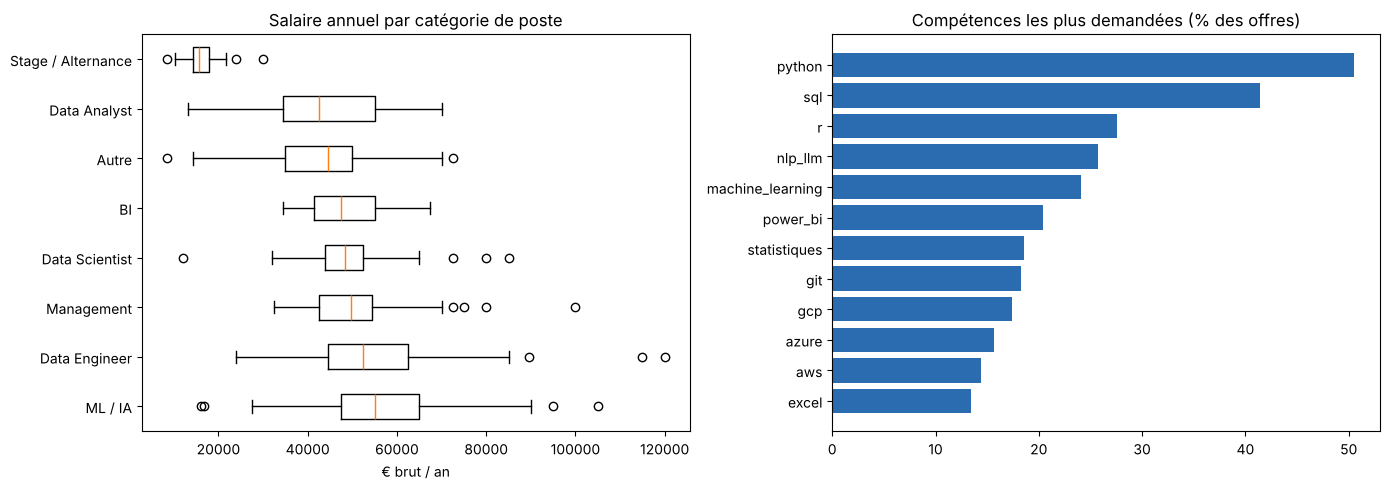

In [14]:
sal_cat = (avec_sal.groupBy("categorie_poste")
           .agg(F.count("*").alias("offres"),
                F.round(F.expr("percentile_approx(salaire_annuel, 0.5)"), 0).alias("salaire_median"),
                F.round(F.avg("salaire_annuel"), 0).alias("salaire_moyen"))
           .orderBy(F.desc("salaire_median")))
sal_cat.show()

pdf_sal = avec_sal.select("categorie_poste", "salaire_annuel").toPandas()
ordre = sal_cat.toPandas()["categorie_poste"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([pdf_sal.loc[pdf_sal.categorie_poste == c, "salaire_annuel"] for c in ordre], tick_labels=ordre, vert=False)
axes[0].set_title("Salaire annuel par catégorie de poste")
axes[0].set_xlabel("€ brut / an")
top_sk = freq_skills.head(12)[::-1]
axes[1].barh(top_sk.index, top_sk["% des offres"], color="#2b6cb0")
axes[1].set_title("Compétences les plus demandées (% des offres)")
plt.tight_layout()
plt.show()

Étape 5 : Modélisation prédictive du salaire (PySpark ML)

Cible : `salaire_annuel` (€ brut / an), disponible seulement pour les offres qui affichent un salaire.
Variables : catégorie de poste, séniorité, contrat, niveau de formation, région, source, années d'expérience (imputées par la médiane), nombre de compétences et 22 indicateurs de compétences.

Les variables catégorielles passent par `StringIndexer` puis `OneHotEncoder` ; le tout est assemblé dans un `VectorAssembler`. Le même pipeline de préparation est partagé par les trois modèles :
1. Régression linéaire (avec régularisation ElasticNet) : modèle de référence, interprétable par ses coefficients ;
2. Random Forest : capte les non-linéarités et les interactions, robuste au bruit ;
3. Gradient Boosted Trees : boosting d'arbres, l'équivalent Spark ML de XGBoost.

Les hyperparamètres de chaque modèle sont choisis par validation croisée à 3 plis sur l'échantillon d'apprentissage (80 %) ; l'évaluation finale se fait sur les 20 % restants. Le jeu de test étant petit (~70 offres), on affiche aussi la RMSE moyenne de validation croisée, plus stable.

In [15]:
CAT_COLS = ["categorie_poste", "niveau_poste", "contrat", "niveau_formation", "region", "source"]
NUM_COLS = ["annees_experience_imp", "nb_skills"] + SKILL_COLS

data = df_clean.filter(F.col("salaire_annuel").isNotNull()).select(CAT_COLS + ["annees_experience", "nb_skills"] + SKILL_COLS + ["salaire_annuel"])
train, test = data.randomSplit([0.8, 0.2], seed=SEED)
train, test = train.cache(), test.cache()
print(f"Offres avec salaire : {data.count()} | apprentissage : {train.count()} | test : {test.count()}")

preparation = [
    Imputer(inputCols=["annees_experience"], outputCols=["annees_experience_imp"], strategy="median"),
    StringIndexer(inputCols=CAT_COLS, outputCols=[c + "_idx" for c in CAT_COLS], handleInvalid="keep"),
    OneHotEncoder(inputCols=[c + "_idx" for c in CAT_COLS], outputCols=[c + "_ohe" for c in CAT_COLS], handleInvalid="keep"),
    VectorAssembler(inputCols=[c + "_ohe" for c in CAT_COLS] + NUM_COLS, outputCol="features"),
]

Offres avec salaire : 451 | apprentissage : 363 | test : 88


In [16]:
evaluateurs = {m: RegressionEvaluator(labelCol="salaire_annuel", predictionCol="prediction", metricName=m) for m in ["rmse", "mae", "r2"]}

lr = LinearRegression(featuresCol="features", labelCol="salaire_annuel")
rf = RandomForestRegressor(featuresCol="features", labelCol="salaire_annuel", seed=SEED)
gbt = GBTRegressor(featuresCol="features", labelCol="salaire_annuel", seed=SEED)

modeles = {
    "Régression linéaire": (lr, ParamGridBuilder()
                            .addGrid(lr.regParam, [0.01, 0.1, 1.0])
                            .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0]).build()),
    "Random Forest": (rf, ParamGridBuilder()
                      .addGrid(rf.numTrees, [100, 200])
                      .addGrid(rf.maxDepth, [5, 8, 12]).build()),
    "Gradient Boosted Trees": (gbt, ParamGridBuilder()
                               .addGrid(gbt.maxDepth, [3, 5])
                               .addGrid(gbt.maxIter, [50, 100])
                               .addGrid(gbt.stepSize, [0.05, 0.1]).build()),
}

resultats, pipelines = [], {}
for nom, (estimateur, grille) in modeles.items():
    cv = CrossValidator(estimator=Pipeline(stages=preparation + [estimateur]),
                        estimatorParamMaps=grille, evaluator=evaluateurs["rmse"], numFolds=3, seed=SEED, parallelism=4)
    modele_cv = cv.fit(train)
    pipelines[nom] = modele_cv.bestModel
    pred = modele_cv.bestModel.transform(test)
    meilleur = modele_cv.bestModel.stages[-1]
    params = {p.name: meilleur.getOrDefault(p) for p in grille[0].keys()}
    resultats.append({"modèle": nom, "RMSE CV (3 plis)": round(min(modele_cv.avgMetrics)), **{m.upper(): round(e.evaluate(pred), 3 if m == "r2" else 0) for m, e in evaluateurs.items()},
                      "meilleurs paramètres": params})
    print(f"{nom} : terminé")

# référence naïve : prédire la médiane de l'apprentissage
mediane = train.approxQuantile("salaire_annuel", [0.5], 0.0)[0]
pred_naif = test.withColumn("prediction", F.lit(mediane))
resultats.append({"modèle": "Référence (médiane)", "RMSE CV (3 plis)": None, **{m.upper(): round(e.evaluate(pred_naif), 3 if m == "r2" else 0) for m, e in evaluateurs.items()},
                  "meilleurs paramètres": {}})
df_resultats = pd.DataFrame(resultats).set_index("modèle")
df_resultats

Régression linéaire : terminé


Random Forest : terminé


Gradient Boosted Trees : terminé


                        RMSE CV (3 plis)     RMSE      MAE     R2  \
modèle                                                              
Régression linéaire              11944.0  10993.0   7789.0  0.633   
Random Forest                    10878.0  11881.0   7952.0  0.571   
Gradient Boosted Trees           11486.0  11327.0   7461.0  0.610   
Référence (médiane)                  NaN  18190.0  13506.0 -0.005   

                                                    meilleurs paramètres  
modèle                                                                    
Régression linéaire            {'regParam': 1.0, 'elasticNetParam': 1.0}  
Random Forest                          {'numTrees': 100, 'maxDepth': 12}  
Gradient Boosted Trees  {'maxDepth': 3, 'maxIter': 50, 'stepSize': 0.05}  
Référence (médiane)                                                   {}  

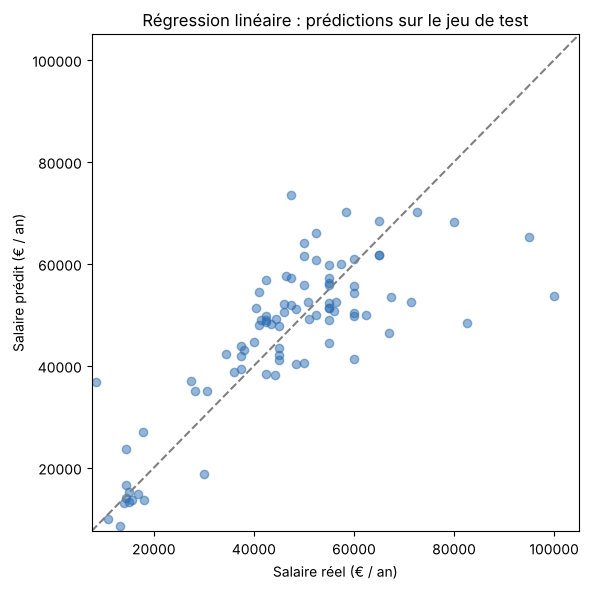

In [17]:
meilleur_nom = df_resultats.drop("Référence (médiane)")["RMSE"].idxmin()
pred_best = pipelines[meilleur_nom].transform(test).select("salaire_annuel", "prediction").toPandas()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pred_best.salaire_annuel, pred_best.prediction, alpha=0.5, color="#2b6cb0")
lim = [pred_best.min().min() * 0.9, pred_best.max().max() * 1.05]
ax.plot(lim, lim, "--", color="grey")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Salaire réel (€ / an)"); ax.set_ylabel("Salaire prédit (€ / an)")
ax.set_title(f"{meilleur_nom} : prédictions sur le jeu de test")
plt.tight_layout()
plt.show()

5.1 Interprétabilité : variables les plus prédictives

- Pour les modèles d'arbres, `featureImportances` mesure la réduction moyenne de variance apportée par chaque variable dans les divisions des arbres. Les importances des modalités d'une même variable catégorielle (issues du one-hot encoding) sont additionnées pour lire l'effet de la variable entière.
- Pour la régression linéaire, les coefficients donnent l'effet de chaque modalité ou compétence en € par an, toutes choses égales par ailleurs.

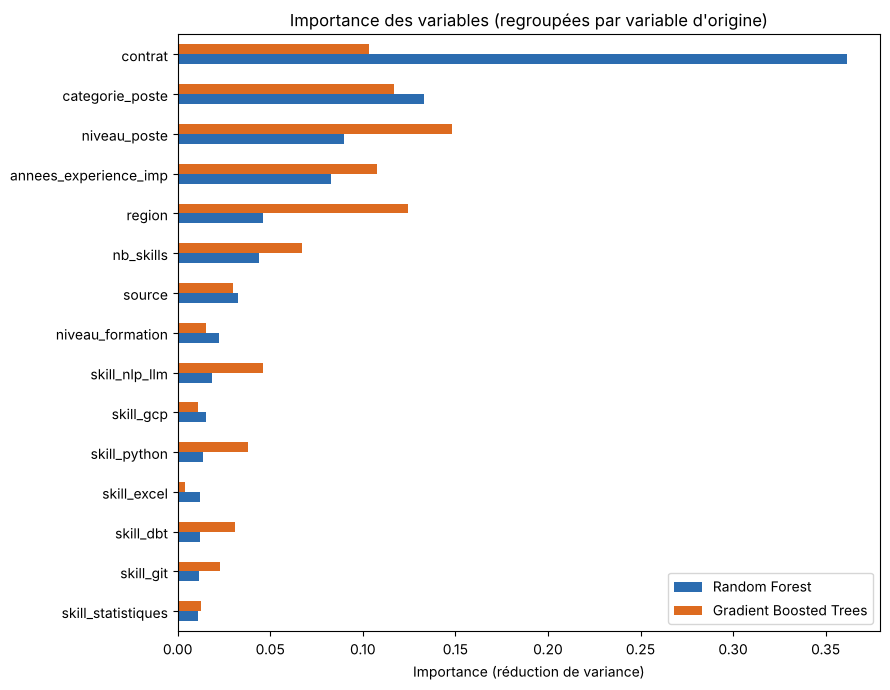

                       Random Forest  Gradient Boosted Trees
contrat                        0.361                   0.103
categorie_poste                0.133                   0.117
niveau_poste                   0.090                   0.148
annees_experience_imp          0.083                   0.108
region                         0.046                   0.124
nb_skills                      0.044                   0.067
source                         0.033                   0.030
niveau_formation               0.022                   0.015
skill_nlp_llm                  0.018                   0.046
skill_gcp                      0.016                   0.011
skill_python                   0.013                   0.038
skill_excel                    0.012                   0.004
skill_dbt                      0.012                   0.031
skill_git                      0.011                   0.023
skill_statistiques             0.011                   0.012

In [18]:
def noms_features(modele_pipeline):
    df_tmp = modele_pipeline.transform(test.limit(1))
    attrs = df_tmp.schema["features"].metadata["ml_attr"]["attrs"]
    noms = {}
    for groupe in attrs.values():
        for a in groupe:
            noms[a["idx"]] = a["name"]
    return [noms[i] for i in range(len(noms))]

def variable_parente(nom):
    for c in CAT_COLS:
        if nom.startswith(c + "_ohe"):
            return c
    return nom

importances = {}
for nom in ["Random Forest", "Gradient Boosted Trees"]:
    m = pipelines[nom]
    imp = pd.Series(m.stages[-1].featureImportances.toArray(), index=noms_features(m))
    importances[nom] = imp.groupby(variable_parente).sum()
imp_df = pd.DataFrame(importances).sort_values("Random Forest", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
imp_df.head(15)[::-1].plot.barh(ax=ax, color=["#2b6cb0", "#dd6b20"])
ax.set_title("Importance des variables (regroupées par variable d'origine)")
ax.set_xlabel("Importance (réduction de variance)")
plt.tight_layout()
plt.show()
imp_df.head(15).round(3)

In [19]:
m_lr = pipelines["Régression linéaire"]
coefs = pd.Series(m_lr.stages[-1].coefficients.toArray(), index=noms_features(m_lr))
coefs = coefs[coefs != 0]
print(f"Intercept : {m_lr.stages[-1].intercept:,.0f} €")
extremes = pd.concat([coefs.sort_values(ascending=False).head(10), coefs.sort_values().head(10)[::-1]])
extremes.rename("effet sur le salaire (€/an)").round(0).to_frame()

Intercept : 39,098 €


                                        effet sur le salaire (€/an)
contrat_ohe_CDI                                             11114.0
niveau_poste_ohe_Lead / Manager                              8324.0
skill_dbt                                                    5353.0
contrat_ohe_CDD / Intérim                                    5257.0
categorie_poste_ohe_Data Engineer                            4880.0
categorie_poste_ohe_Stage / Alternance                       4638.0
region_ohe_Non renseigné                                     4512.0
skill_nlp_llm                                                4144.0
skill_python                                                 3820.0
skill_spark                                                  3471.0
skill_git                                                   -3036.0
region_ohe_Autres régions                                   -3170.0
skill_sql                                                   -3393.0
niveau_formation_ohe_Bac+2 et moins             

5.2 Conclusion

Performances. Les trois modèles font nettement mieux que la référence naïve (prédire la médiane) : l'erreur absolue moyenne passe d'environ 13 500 € à 7 500-8 000 € par an, et le R² sur le jeu de test se situe entre 0,57 et 0,63. Les écarts entre les modèles sont faibles et leur classement dépend du critère : le Random Forest a la meilleure RMSE en validation croisée, la régression linéaire la meilleure RMSE et le meilleur R² sur le jeu de test, et le GBT (l'équivalent Spark ML de XGBoost) la plus petite erreur absolue moyenne. Avec un jeu de test de 88 offres, ces différences tiennent en partie au hasard du découpage ; la validation croisée, calculée sur trois découpages, est le critère le plus fiable et désigne le Random Forest. Le fait qu'une régression linéaire fasse presque aussi bien montre que l'essentiel du signal tient en quelques effets additifs (contrat, métier, séniorité).

Variables les plus prédictives. Les modèles d'arbres et la régression linéaire s'accordent :
1. le type de contrat : un stage ou une alternance divise le salaire par 3 environ, un CDI est mieux payé qu'un CDD ou une mission d'intérim ;
2. la catégorie de poste : les profils ML / IA (médiane 55 000 €) et Data Engineer (52 500 €) sont les mieux rémunérés, les Data Analysts (42 500 €) en dessous ;
3. la séniorité et l'expérience : un intitulé « Lead / Manager » ajoute environ 8 000 €, un intitulé « Junior » en retire environ 12 000 ;
4. dans une moindre mesure la région et le niveau de diplôme.

Prises une à une, les compétences pèsent moins : elles sont surtout le reflet du métier. Python est désormais demandé dans une offre sur deux et SQL dans quatre sur dix. Les outils du cloud et de la « modern data stack » (dbt, GCP, Azure, Spark, Databricks) et l'IA générative (NLP / LLM) sont associés à des salaires plus élevés, tandis qu'Excel et Power BI sont associés à des postes moins rémunérés.

Limites.
- Environ une offre sur cinq seulement affiche un salaire : l'échantillon d'apprentissage est petit et biaisé (les entreprises qui affichent un salaire ne sont pas représentatives), ce qui limite le R² et rend les métriques sensibles au découpage.
- Les coefficients de la régression linéaire doivent être lus avec prudence quand une compétence est rare (SAS, Hadoop) ou corrélée à d'autres : ils sont instables.
- Les compétences sont détectées par mots-clés : une approche TF-IDF ou des embeddings sur les descriptions permettrait d'aller plus loin.
- Les taux journaliers des freelances ont été exclus de la cible ; un modèle dédié serait nécessaire pour les étudier.

In [20]:
spark.stop()